# Multi-Disease Risk Prediction System
## Notebook 02: Supervised, Unsupervised, Probabilistic Learning & Generative AI Explanation
**Academic Coursework:** Machine Learning Project  
**Syllabus Coverage:** **UNIT III, UNIT IV & UNIT V**  
- **UNIT III:** Supervised Learning (kNN, Logistic Regression, Decision Tree, Random Forest) & Evaluation Metrics (Accuracy, Precision, Recall, F1, Confusion Matrix, ROC curves, Recall prioritization)
- **UNIT IV:** Unsupervised & Probabilistic Learning (k-Means, Elbow & Silhouette, Hierarchical Clustering Dendrogram, Gaussian Naive Bayes)
- **UNIT V:** Generative AI / LLM Explanation (Plain-language clinical risk synthesis with Gemini API & Offline Fallback)


In [1]:
# Imports & Configuration
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, silhouette_score
)

# Add parent directory to path to access src package
sys.path.append(os.path.abspath('..'))
from src.preprocess import load_data, split_data, build_full_pipeline, DISEASE_METADATA
from src.train import tune_knn_k, train_and_evaluate_disease
from src.predict import predict_risk, what_if_simulation
from src.explain import explain_prediction

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#E5E7EB'
PRIMARY_COLOR = '#0F766E'
ACCENT_COLOR = '#D97706'
DANGER_COLOR = '#DC2626'
PALETTE = ['#0F766E', '#DC2626']

print("Notebook environment configured successfully!")


Notebook environment configured successfully!


C:\Users\Admin\disease-predictor\src\explain.py:12: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


---
## 1. Supervised Learning: Diabetes Risk Modeling (UNIT III)
### 1.1 Hyperparameter Tuning: kNN (Accuracy vs K)
We evaluate $K \in [1, 25]$ using 5-fold cross-validation on the preprocessed training set.


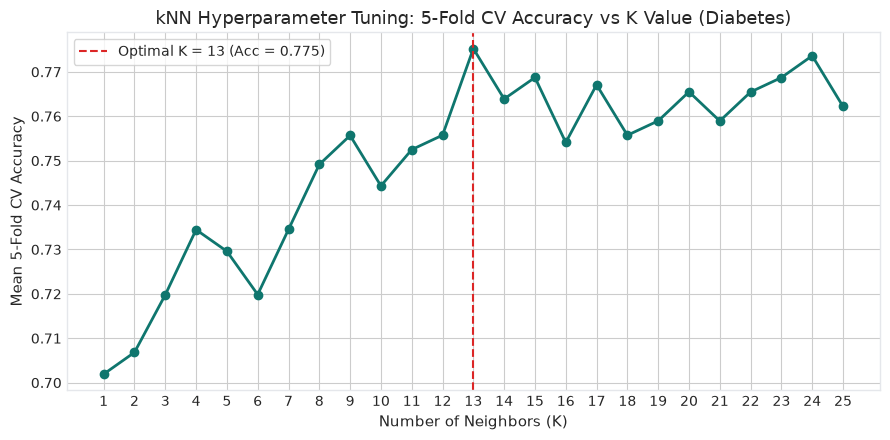

In [2]:
# Evaluate kNN across K values
from src.preprocess import build_column_preprocessor

X_diab, y_diab = load_data('diabetes')
X_d_train, X_d_test, y_d_train, y_d_test = split_data(X_diab, y_diab, test_size=0.2, random_state=42)
preproc_diab = build_column_preprocessor('diabetes')

best_k, k_scores = tune_knn_k(X_d_train, y_d_train, preproc_diab)

# Plot Accuracy vs K
plt.figure(figsize=(9, 4.5))
plt.plot(list(k_scores.keys()), list(k_scores.values()), marker='o', color=PRIMARY_COLOR, linewidth=2, markersize=6)
plt.axvline(best_k, color=DANGER_COLOR, linestyle='--', label=f'Optimal K = {best_k} (Acc = {k_scores[best_k]:.3f})')
plt.title('kNN Hyperparameter Tuning: 5-Fold CV Accuracy vs K Value (Diabetes)', fontsize=13)
plt.xlabel('Number of Neighbors (K)', fontsize=11)
plt.ylabel('Mean 5-Fold CV Accuracy', fontsize=11)
plt.xticks(list(k_scores.keys()))
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### 1.2 Model Comparison & Medical Recall Prioritization
In clinical diagnostics, **Recall (Sensitivity)** is prioritized over simple accuracy.
$$\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}$$
A **False Negative** means a diseased individual is told they are healthy, delaying critical medical intervention. In contrast, a **False Positive** triggers an inexpensive follow-up test (e.g. repeated fasting plasma glucose test or HbA1c panel). Therefore, we prioritize Recall as the leading decision criterion.


In [3]:
# Train and evaluate all 5 models on Diabetes
art_diab = train_and_evaluate_disease('diabetes', models_dir='../models')
print("\n--- Model Comparison Table (Diabetes) ---")
display(art_diab['metrics_df'])
print("\nSelected Best Model:", art_diab['best_model_name'])
print("Clinical Justification:\n", art_diab['selection_reason'])



Training models for disease: DIABETES
Evaluating kNN across K values (1 to 25)...


Optimal K for kNN: 13 (CV Accuracy: 0.7752)



Model Evaluation Comparison Table (Test Set):
                     Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC  CV Recall
k-Nearest Neighbors (K=13)  0.714286   0.608696 0.518519  0.560000 0.794444   0.603212
       Logistic Regression  0.707792   0.600000 0.500000  0.545455 0.812963   0.574751
             Decision Tree  0.759740   0.639344 0.722222  0.678261 0.762222   0.560244
             Random Forest  0.772727   0.702128 0.611111  0.653465 0.818056   0.584275
      Gaussian Naive Bayes  0.701299   0.566667 0.629630  0.596491 0.764630   0.598450

Best Model: Decision Tree
Reason: Selected Decision Tree as the primary clinical model because it achieved the highest Recall (72.2%) on held-out data. In medical screening, prioritizing Recall minimizes dangerous False Negatives (missed diagnoses), while False Positives can be safely adjudicated via follow-up diagnostic tests.

Fitting Unsupervised Clustering (k-Means & Hierarchical)...


Cluster 1: Low Risk Cluster (13.1% disease prevalence, n=335)
Cluster 0: Moderate Risk Cluster (51.6% disease prevalence, n=248)
Cluster 2: High Risk Cluster (51.9% disease prevalence, n=185)
Saved complete artifact to ../models\diabetes_model.joblib (1768.5 KB)

--- Model Comparison Table (Diabetes) ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Recall
0,k-Nearest Neighbors (K=13),0.714286,0.608696,0.518519,0.560000,0.794444,0.603212
1,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963,0.574751
2,Decision Tree,0.759740,0.639344,0.722222,0.678261,0.762222,0.560244
3,Random Forest,0.772727,0.702128,0.611111,0.653465,0.818056,0.584275
4,Gaussian Naive Bayes,0.701299,0.566667,0.629630,0.596491,0.764630,0.598450



Selected Best Model: Decision Tree
Clinical Justification:
 Selected Decision Tree as the primary clinical model because it achieved the highest Recall (72.2%) on held-out data. In medical screening, prioritizing Recall minimizes dangerous False Negatives (missed diagnoses), while False Positives can be safely adjudicated via follow-up diagnostic tests.


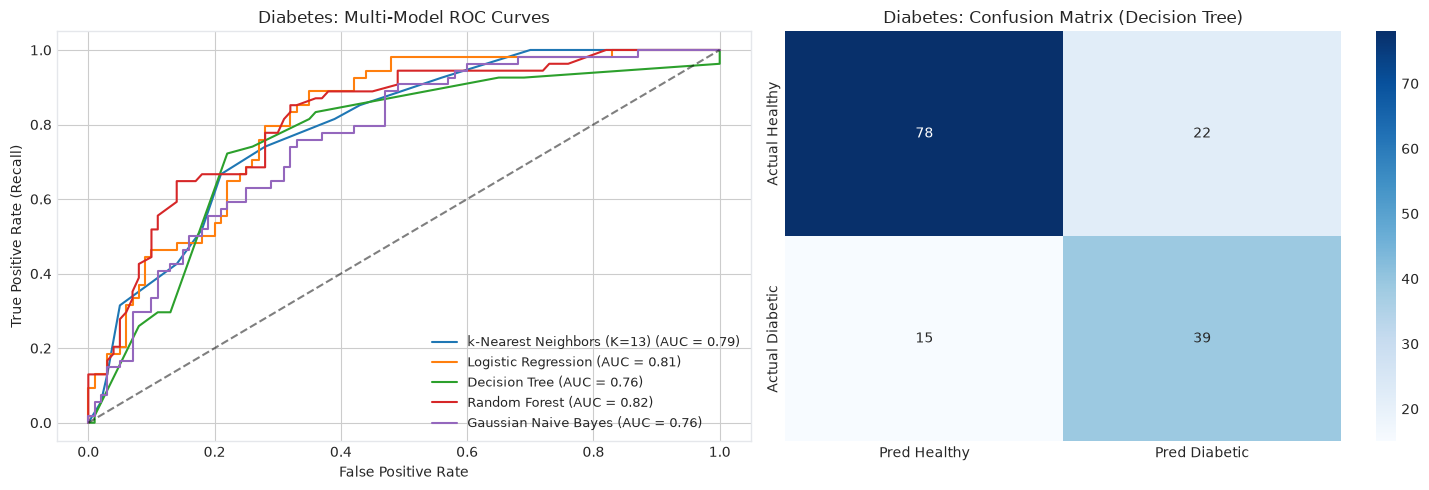

In [4]:
# ROC Curves and Confusion Matrix for Best Model (Diabetes)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Multi-model ROC Curves
for name, roc_data in art_diab['roc_curves'].items():
    axes[0].plot(roc_data['fpr'], roc_data['tpr'], label=f"{name} (AUC = {roc_data['auc']:.2f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Diabetes: Multi-Model ROC Curves', fontsize=12)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', fontsize=9)

# Confusion Matrix for Best Model
best_name = art_diab['best_model_name']
cm = np.array(art_diab['confusion_matrices'][best_name])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Pred Healthy', 'Pred Diabetic'],
            yticklabels=['Actual Healthy', 'Actual Diabetic'])
axes[1].set_title(f'Diabetes: Confusion Matrix ({best_name})', fontsize=12)

plt.tight_layout()
plt.show()


---
## 2. Supervised Learning Across All Diseases (Heart, Kidney, Cancer)
We train and evaluate the full suite of 5 models on the remaining 3 diseases:


In [5]:
# Train remaining diseases and display comparison tables
diseases = ['heart', 'kidney', 'cancer']
artifacts = {'diabetes': art_diab}

for d in diseases:
    art = train_and_evaluate_disease(d, models_dir='../models')
    artifacts[d] = art
    print(f"\n=== {d.upper()} MODEL COMPARISON TABLE ===")
    display(art['metrics_df'])
    print(f"Best Model for {d.upper()}: {art['best_model_name']} (Recall = {art['metrics_df'].loc[art['metrics_df']['Model'] == art['best_model_name'], 'Recall'].values[0]:.1%})")



Training models for disease: HEART
Evaluating kNN across K values (1 to 25)...


Optimal K for kNN: 15 (CV Accuracy: 0.8638)



Model Evaluation Comparison Table (Test Set):
                     Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC  CV Recall
k-Nearest Neighbors (K=15)  0.891304   0.879630 0.931373  0.904762 0.936334   0.891659
       Logistic Regression  0.885870   0.885714 0.911765  0.898551 0.933883   0.871966
             Decision Tree  0.788043   0.811881 0.803922  0.807882 0.845827   0.847275
             Random Forest  0.885870   0.878505 0.921569  0.899522 0.931612   0.889310
      Gaussian Naive Bayes  0.869565   0.890000 0.872549  0.881188 0.907102   0.849804

Best Model: k-Nearest Neighbors (K=15)
Reason: Selected k-Nearest Neighbors (K=15) as the primary clinical model because it achieved the highest Recall (93.1%) on held-out data. In medical screening, prioritizing Recall minimizes dangerous False Negatives (missed diagnoses), while False Positives can be safely adjudicated via follow-up diagnostic tests.

Fitting Unsupervised Clustering (k-Means & Hierarchical)...


Cluster 2: Low Risk Cluster (19.0% disease prevalence, n=384)
Cluster 1: Moderate Risk Cluster (81.2% disease prevalence, n=330)
Cluster 0: High Risk Cluster (81.9% disease prevalence, n=204)
Saved complete artifact to ../models\heart_model.joblib (2006.6 KB)

=== HEART MODEL COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Recall
0,k-Nearest Neighbors (K=15),0.891304,0.879630,0.931373,0.904762,0.936334,0.891659
1,Logistic Regression,0.885870,0.885714,0.911765,0.898551,0.933883,0.871966
2,Decision Tree,0.788043,0.811881,0.803922,0.807882,0.845827,0.847275
3,Random Forest,0.885870,0.878505,0.921569,0.899522,0.931612,0.889310
4,Gaussian Naive Bayes,0.869565,0.890000,0.872549,0.881188,0.907102,0.849804


Best Model for HEART: k-Nearest Neighbors (K=15) (Recall = 93.1%)

Training models for disease: KIDNEY
Evaluating kNN across K values (1 to 25)...


... (6 outputs left out)


Model Evaluation Comparison Table (Test Set):
                    Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC  CV Recall
k-Nearest Neighbors (K=3)  0.938596   0.972973 0.857143  0.911392 0.982474   0.935294
      Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996032   0.952941
            Decision Tree  0.921053   0.945946 0.833333  0.886076 0.944775   0.852941
            Random Forest  0.973684   1.000000 0.928571  0.962963 0.992890   0.941176
     Gaussian Naive Bayes  0.921053   0.923077 0.857143  0.888889 0.989087   0.911765

Best Model: Random Forest
Reason: Selected Random Forest as the primary clinical model because it achieved the highest Recall (92.9%) on held-out data. In medical screening, prioritizing Recall minimizes dangerous False Negatives (missed diagnoses), while False Positives can be safely adjudicated via follow-up diagnostic tests.

Fitting Unsupervised Clustering (k-Means & Hierarchical)...


Cluster 1: Low Risk Cluster (10.6% disease prevalence, n=359)
Cluster 2: Moderate Risk Cluster (64.0% disease prevalence, n=100)
Cluster 0: High Risk Cluster (100.0% disease prevalence, n=110)
Saved complete artifact to ../models\cancer_model.joblib (477.5 KB)

=== CANCER MODEL COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Recall
0,k-Nearest Neighbors (K=3),0.938596,0.972973,0.857143,0.911392,0.982474,0.935294
1,Logistic Regression,0.964912,0.975000,0.928571,0.951220,0.996032,0.952941
2,Decision Tree,0.921053,0.945946,0.833333,0.886076,0.944775,0.852941
3,Random Forest,0.973684,1.000000,0.928571,0.962963,0.992890,0.941176
4,Gaussian Naive Bayes,0.921053,0.923077,0.857143,0.888889,0.989087,0.911765


Best Model for CANCER: Random Forest (Recall = 92.9%)


---
## 3. Unsupervised Learning: Risk Clustering & Dendrograms (UNIT IV)
### 3.1 k-Means Clustering: Elbow Method & Silhouette Analysis
We determine optimal cluster counts by inspecting the sum of squared distances (Inertia) and the Silhouette coefficient for $K \in [2, 6]$.


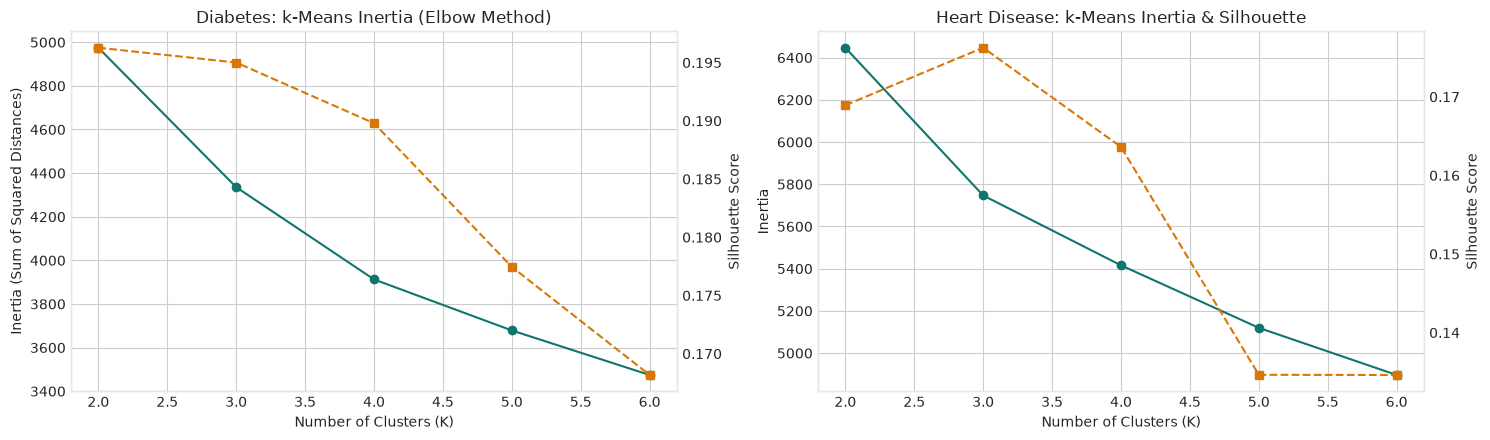

In [6]:
# Elbow and Silhouette plots for Diabetes and Heart Disease
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

k_eval_diab = art_diab['kmeans_eval']
axes[0].plot(k_eval_diab['k_range'], k_eval_diab['inertia'], marker='o', color=PRIMARY_COLOR, label='Inertia (Elbow)')
axes[0].set_title('Diabetes: k-Means Inertia (Elbow Method)', fontsize=12)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Sum of Squared Distances)')

# Silhouette score on second axis
ax2 = axes[0].twinx()
ax2.plot(k_eval_diab['k_range'], k_eval_diab['silhouette'], marker='s', color=ACCENT_COLOR, linestyle='--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score')
ax2.grid(False)

# Heart Disease Elbow & Silhouette
art_heart = artifacts['heart']
k_eval_heart = art_heart['kmeans_eval']
axes[1].plot(k_eval_heart['k_range'], k_eval_heart['inertia'], marker='o', color=PRIMARY_COLOR, label='Inertia')
axes[1].set_title('Heart Disease: k-Means Inertia & Silhouette', fontsize=12)
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Inertia')

ax3 = axes[1].twinx()
ax3.plot(k_eval_heart['k_range'], k_eval_heart['silhouette'], marker='s', color=ACCENT_COLOR, linestyle='--', label='Silhouette')
ax3.set_ylabel('Silhouette Score')
ax3.grid(False)

plt.tight_layout()
plt.show()


### 3.2 Cluster Risk Profiling
Clusters formed by k-Means ($K=3$) are labeled as **Low Risk**, **Moderate Risk**, or **High Risk** according to the empirical proportion of positive disease cases belonging to each cluster.


In [7]:
# Display Cluster Risk Profiles
for d_name in ['diabetes', 'heart', 'kidney', 'cancer']:
    print(f"\n=== {d_name.upper()} RISK CLUSTERS ===")
    cmap = artifacts[d_name]['cluster_risk_map']
    for c_id, c_data in cmap.items():
        print(f"Cluster {c_id}: {c_data.get('label', 'Cluster')} -> Size={c_data['size']}, Positives={c_data['positive_count']} ({c_data['positive_rate']:.1%} prevalence)")



=== DIABETES RISK CLUSTERS ===
Cluster 0: Moderate Risk Cluster -> Size=248, Positives=128 (51.6% prevalence)
Cluster 1: Low Risk Cluster -> Size=335, Positives=44 (13.1% prevalence)
Cluster 2: High Risk Cluster -> Size=185, Positives=96 (51.9% prevalence)

=== HEART RISK CLUSTERS ===
Cluster 0: High Risk Cluster -> Size=204, Positives=167 (81.9% prevalence)
Cluster 1: Moderate Risk Cluster -> Size=330, Positives=268 (81.2% prevalence)
Cluster 2: Low Risk Cluster -> Size=384, Positives=73 (19.0% prevalence)

=== KIDNEY RISK CLUSTERS ===
Cluster 0: Moderate Risk Cluster -> Size=161, Positives=161 (100.0% prevalence)
Cluster 1: Low Risk Cluster -> Size=202, Positives=52 (25.7% prevalence)
Cluster 2: High Risk Cluster -> Size=37, Positives=37 (100.0% prevalence)

=== CANCER RISK CLUSTERS ===
Cluster 0: High Risk Cluster -> Size=110, Positives=110 (100.0% prevalence)
Cluster 1: Low Risk Cluster -> Size=359, Positives=38 (10.6% prevalence)
Cluster 2: Moderate Risk Cluster -> Size=100, Posi

### 3.3 Hierarchical Clustering Dendrogram
Using Ward's minimum variance method on preprocessed clinical feature spaces, we visualize sample patient dendrograms.


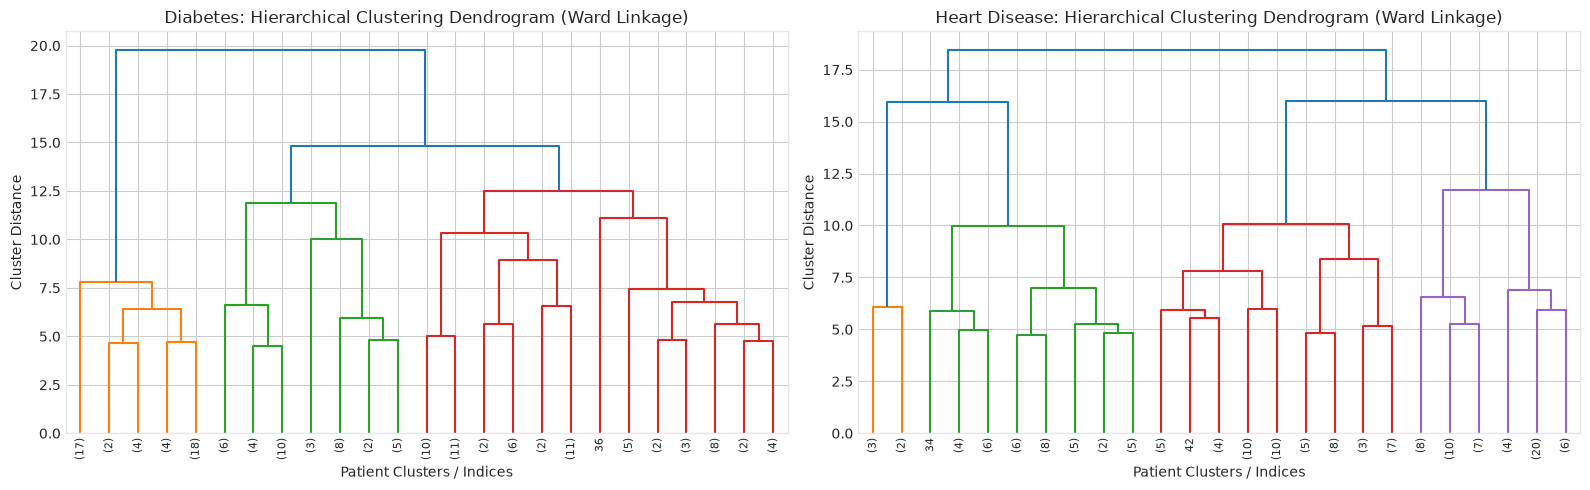

In [8]:
# Hierarchical Clustering Dendrogram (Diabetes & Heart)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

dendrogram(art_diab['linkage_matrix'], ax=axes[0], truncate_mode='lastp', p=25, leaf_rotation=90, leaf_font_size=8)
axes[0].set_title('Diabetes: Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=12)
axes[0].set_xlabel('Patient Clusters / Indices')
axes[0].set_ylabel('Cluster Distance')

dendrogram(art_heart['linkage_matrix'], ax=axes[1], truncate_mode='lastp', p=25, leaf_rotation=90, leaf_font_size=8)
axes[1].set_title('Heart Disease: Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=12)
axes[1].set_xlabel('Patient Clusters / Indices')
axes[1].set_ylabel('Cluster Distance')

plt.tight_layout()
plt.show()


### 3.4 Probabilistic Learning: Gaussian Naive Bayes Deep Dive
Gaussian Naive Bayes applies Bayes' Theorem with the naive assumption of conditional independence between features given the class:
$$P(Y = c \mid X) = \frac{P(Y = c) \prod_{i=1}^n P(X_i \mid Y = c)}{P(X)}$$
Where $P(X_i \mid Y = c) \sim \mathcal{N}(\mu_{c,i}, \sigma_{c,i}^2)$.


In [9]:
# Gaussian Naive Bayes Class Probabilities for a Sample Patient
sample_patient = {
    'Pregnancies': 3,
    'Glucose': 165.0,
    'BloodPressure': 82.0,
    'SkinThickness': 32.0,
    'Insulin': 160.0,
    'BMI': 35.8,
    'DiabetesPedigreeFunction': 0.62,
    'Age': 48
}

gnb_pipe = art_diab['all_models']['Gaussian Naive Bayes']
sample_df = pd.DataFrame([sample_patient])
gnb_proba = gnb_pipe.predict_proba(sample_df)[0]

print("Gaussian Naive Bayes Probabilities:")
print(f" - P(Healthy | X) = {gnb_proba[0]:.4f} ({gnb_proba[0]*100:.1f}%)")
print(f" - P(Diabetic | X) = {gnb_proba[1]:.4f} ({gnb_proba[1]*100:.1f}%)")


Gaussian Naive Bayes Probabilities:
 - P(Healthy | X) = 0.0880 (8.8%)
 - P(Diabetic | X) = 0.9120 (91.2%)


---
## 4. Generative AI / LLM Clinical Explanation (UNIT V)
We synthesize the quantitative outputs (supervised risk percentage, feature contributions, and unsupervised risk cluster) into an empathetic, clear, plain-language patient report.
- Powered by **Google Generative AI (Gemini)** when `GEMINI_API_KEY` is present.
- Equipped with a **Deterministic Clinical Fallback Engine** so the pipeline never breaks if offline.


In [10]:
# Run Prediction & Generative Explanation
prediction_out = predict_risk('diabetes', sample_patient, models_dir='../models')
explanation_out = explain_prediction('diabetes', sample_patient, prediction_out)

print("Prediction Summary:")
print(f" - Risk Level: {prediction_out['risk_level']} ({prediction_out['risk_percentage']}%)")
print(f" - Risk Cluster: {prediction_out['cluster_label']}")
print(f" - Model Used: {prediction_out['model_name']}")
print(f" - Explanation Source: {explanation_out['source']}")

print("\n--- Generated Clinical Report ---")
from IPython.display import Markdown
display(Markdown(explanation_out['explanation']))


Prediction Summary:
 - Risk Level: High Risk (90.1%)
 - Risk Cluster: Moderate Risk Cluster
 - Model Used: Decision Tree
 - Explanation Source: Clinical Rule Engine (Offline Fallback)

--- Generated Clinical Report ---


### Clinical Overview
Based on your input parameters, the predictive model estimates your **Diabetes Risk** risk at **90.1%**, placing you in the **High Risk** category. In addition, unsupervised clustering grouped your profile with the **Moderate Risk Cluster** (where the historical cohort prevalence was 51.6%).

### Primary Risk Drivers
The top clinical factors influencing this prediction include:
- **Fasting Plasma Glucose (mg/dL) (165.0)**: Currently marked as *elevated* relative to baseline healthy controls, contributing heavily to the risk score.
- **Age (years) (48.0)**: Currently marked as *elevated* relative to baseline healthy controls, contributing heavily to the risk score.
- **Body Mass Index (kg/m²) (35.8)**: Currently marked as *elevated* relative to baseline healthy controls, contributing heavily to the risk score.


### Protective & Stabilizing Factors
Parameters that aligned with healthy normative ranges serve as positive clinical stabilizers. Keeping these within target boundaries helps buffer overall health risk.

### Actionable Next Steps & Questions for Your Doctor
- Focus on complex carbohydrates with low glycemic index, maintain consistent physical activity (aim for 150 minutes of moderate aerobic exercise weekly), and monitor fasting blood glucose levels regularly.
- Bring this parameter summary to your next physician visit to discuss whether confirmatory lab tests (e.g. HbA1c, full lipid profile, or renal panel) are recommended.
- Explore gradual, sustainable adjustments to the modifiable lifestyle factors shown in the What-If analysis.

> *Source: Clinical Rule Engine (Offline Fallback — set GEMINI_API_KEY to activate Live LLM).*


In [11]:
# Interactive What-If Sensitivity Test
what_if_res = what_if_simulation('diabetes', sample_patient, {'Glucose': 105.0, 'BMI': 24.0}, models_dir='../models')
print("What-If Simulation Results:")
print(f" - Baseline Risk: {what_if_res['base_risk_pct']}%")
print(f" - Modified Risk: {what_if_res['modified_risk_pct']}%")
print(f" - Absolute Risk Reduction: {what_if_res['delta_pct']}%")


What-If Simulation Results:
 - Baseline Risk: 90.1%
 - Modified Risk: 1.0%
 - Absolute Risk Reduction: -89.2%
